# Module 2 — Advanced Classification: Support Vector Machines

Classificazione del **Severity Impairment Index (`sii`, 4 classi)** con SVM lineari e non lineari.

Il preprocessing (split, scaling, encoding) è **identico** a quello dei notebook di Logistic Regression e Neural
Networks, così i risultati dei classificatori del Modulo 2 sono confrontabili sullo stesso test set.

**Struttura**
1. Setup
2. Caricamento dati e preprocessing (comune al Modulo 2)
3. Funzioni di valutazione
4. PCA: visualizzazione delle classi
5. SVM lineare: tuning, support vector, effetto di `C`
6. SVM non lineare: kernel RBF, polinomiale e sigmoide
7. Effetto di `class_weight`
8. Analisi del modello migliore
9. Confronto finale e confronto con LR e NN
10. Sintesi per il report

> **Legenda.** I blocchi **📌 Report** indicano cosa riportare nel report (tabelle, grafici, frasi chiave).
> I numeri citati nei commenti vengono dal run di riferimento.

**Tempo di esecuzione**: circa 10 minuti su CPU (quasi tutto nella ricerca degli iperparametri dei kernel, sezione 6).

**Modifiche rispetto alla versione precedente del notebook**
- split **80/20 con `random_state=42`** (prima 70/30 con `random_state=100`), uguale a LR e NN;
- scaling e one-hot encoding dentro una `Pipeline` con `ColumnTransformer`: lo scaler viene fittato dentro ogni
  fold della cross-validation (prima era fittato su tutto il training prima della `GridSearchCV`, con un piccolo
  data leakage);
- le dummy delle colonne `Season` non vengono più standardizzate (come nella LR);
- `class_weight` incluso nella griglia di **tutti** i modelli (prima veniva solo applicato al kernel migliore,
  senza rifare il tuning);
- aggiunte balanced accuracy e ROC AUC macro, come negli altri notebook;
- eliminate le righe duplicate nella tabella dei risultati.

## 1. Setup

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score,
                             precision_recall_curve, average_precision_score)

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (7, 5)
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

## 2. Caricamento dati e preprocessing

Stesso codice dei notebook di Logistic Regression e Neural Networks: split stratificato 80/20 con
`random_state=42`, `StandardScaler` sulle numeriche e `OneHotEncoder(drop='first')` sulle 10 colonne `Season`,
dentro un `ColumnTransformer` fittato solo sul train (anche dentro ogni fold della cross-validation).

Per le SVM lo scaling è indispensabile: sia il margine sia i kernel RBF, polinomiale e sigmoide dipendono dalle
distanze o dai prodotti scalari fra punti, che senza scaling sarebbero dominati dalle feature con valori più grandi.

`sii` deriva da `PCIAT_Total`; tutte le colonne `PCIAT_*` sono state eliminate in Data Preparation, quindi non c'è
target leakage.

In [2]:
df = pd.read_csv('cmi_internet_final.csv')
print('Shape:', df.shape, '| valori mancanti:', df.isna().sum().sum())

y = df['sii']
X = df.drop(columns=['id', 'sii'])

cat_cols = [c for c in X.columns if 'Season' in c]
num_cols = [c for c in X.columns if c not in cat_cols]
print(f'{len(num_cols)} feature numeriche, {len(cat_cols)} categoriche')

dist = y.value_counts().sort_index()
print(pd.DataFrame({'n': dist, '%': (dist / len(y) * 100).round(2)}))

Shape: (8460, 50) | valori mancanti: 0
38 feature numeriche, 10 categoriche
        n      %
sii             
0    5833  68.95
1    1587  18.76
2     952  11.25
3      88   1.04


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Classi nel test:', y_test.value_counts().sort_index().to_dict())

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CLASSI = [0, 1, 2, 3]
NOMI_CLASSI = {0: '0 - None', 1: '1 - Mild', 2: '2 - Moderate', 3: '3 - Severe'}

Train: (6768, 48) | Test: (1692, 48)
Classi nel test: {0: 1167, 1: 317, 2: 190, 3: 18}


## 3. Funzioni di valutazione

Su un target così sbilanciato (classe 3 ≈ 1%) l'accuracy è fuorviante: il classificatore banale ottiene già il 69%.
La metrica usata per il tuning e per scegliere i modelli è la **F1-macro**; accanto si riportano accuracy,
balanced accuracy, ROC AUC macro e la F1 di ogni classe, con le stesse colonne degli altri notebook del Modulo 2.

**ROC AUC con le SVM.** `SVC` non fornisce probabilità (servirebbe `probability=True`, che rifà il training con
una 5-fold interna e moltiplica i tempi). L'AUC one-vs-rest però dipende solo dall'**ordinamento** dei punti, quindi
si può calcolare direttamente dagli score di `decision_function`: per ogni classe si calcola l'AUC "classe k contro
il resto" sugli score di quella classe e si fa la media. È la stessa definizione di `roc_auc_score(...,
multi_class='ovr', average='macro')`.

In [4]:
risultati = []

def auc_ovr(scores, y_true=None):
    """ROC AUC macro one-vs-rest calcolata dagli score di decision_function."""
    y_true = y_test if y_true is None else y_true
    return np.mean([roc_auc_score(y_true == k, scores[:, i]) for i, k in enumerate(CLASSI)])


def valuta(nome, modello, stampa=True):
    y_pred = modello.predict(X_test)
    scores = modello.decision_function(X_test)
    f1_classi = f1_score(y_test, y_pred, average=None, labels=CLASSI, zero_division=0)
    res = {
        'modello': nome,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_acc': balanced_accuracy_score(y_test, y_pred),
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'roc_auc': auc_ovr(scores),
    }
    for k, v in zip(CLASSI, f1_classi):
        res[f'f1_{k}'] = v
    risultati.append(res)
    if stampa:
        print(f'=== {nome} ===')
        print({k: round(float(v), 3) for k, v in res.items() if k != 'modello'})
        print(classification_report(y_test, y_pred, digits=3, zero_division=0))
    return y_pred


def plot_confusion(y_pred, titolo):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASSI, colorbar=False)
    plt.title(titolo); plt.tight_layout(); plt.show()


def plot_roc_pr(scores, titolo):
    """Curve ROC e Precision-Recall one-vs-rest, una per classe, dagli score di decision_function."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for i, k in enumerate(CLASSI):
        y_bin = (y_test == k).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, scores[:, i])
        axes[0].plot(fpr, tpr, color=COLORS[i], label=f'classe {k} (AUC = {auc(fpr, tpr):.2f})')
        prec, rec, _ = precision_recall_curve(y_bin, scores[:, i])
        ap = average_precision_score(y_bin, scores[:, i])
        axes[1].plot(rec, prec, color=COLORS[i], label=f'classe {k} (AP = {ap:.2f}, base = {y_bin.mean():.2f})')
    axes[0].plot([0, 1], [0, 1], 'k--', lw=.8)
    axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC one-vs-rest'); axes[0].legend(fontsize=8)
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].set_title('Precision-Recall one-vs-rest'); axes[1].legend(fontsize=8)
    plt.suptitle(titolo); plt.tight_layout(); plt.show()


def tabella_cv(gs, params):
    """Tabella dei risultati della GridSearchCV, ordinata per F1-macro in CV."""
    cols = ['param_' + p for p in params] + ['mean_test_score', 'std_test_score', 'rank_test_score']
    tab = (pd.DataFrame(gs.cv_results_)[cols]
           .rename(columns=lambda c: c.replace('param_clf__', ''))
           .sort_values('rank_test_score'))
    if 'class_weight' in tab:
        tab['class_weight'] = tab['class_weight'].fillna('None')
    return tab

## 4. PCA: visualizzazione delle classi

Due componenti principali estratte dal training set (già preprocessato), solo a scopo di visualizzazione, per avere
una prima idea di quanto le classi siano separabili.

Varianza spiegata: [0.161 0.074] | totale: 0.235


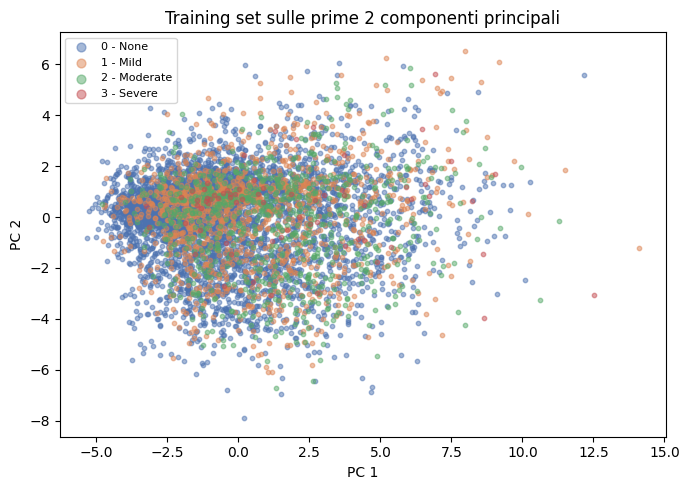

In [5]:
prep_vis = clone(preprocessor).fit(X_train)       # solo per le visualizzazioni
X_train_p = prep_vis.transform(X_train)

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_p)
X_pca = pca.transform(X_train_p)
print('Varianza spiegata:', pca.explained_variance_ratio_.round(3),
      '| totale:', pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(7, 5))
for i, k in enumerate(CLASSI):
    m = (y_train == k).values
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=.5, c=COLORS[i], label=NOMI_CLASSI[k])
plt.xlabel('PC 1'); plt.ylabel('PC 2'); plt.title('Training set sulle prime 2 componenti principali')
plt.legend(markerscale=2, fontsize=8); plt.tight_layout(); plt.show()

**Commento.** Le prime due componenti spiegano solo il **23,5%** della varianza, e nel piano le quattro classi sono completamente sovrapposte: i punti delle classi 1, 2 e 3 sono sparsi dentro la nuvola della classe 0, senza zone dominate da una singola classe. Ci si può aspettare già da qui che nessun iperpiano (né frontiera non lineare) separi bene le classi.

📌 **Report:** il grafico PCA è utile come prima figura della sezione SVM per motivare risultati modesti.

## 5. SVM lineare

`LinearSVC` è preferito a `SVC(kernel='linear')`: si basa su *liblinear* e scala molto meglio con il numero di
esempi. Con 4 classi usa uno schema one-vs-rest.

Grid search con 5-fold stratificata su F1-macro:

| Parametro | Valori | Motivazione |
|---|---|---|
| `C` | 0.001 → 100 (scala logaritmica) | compromesso fra ampiezza del margine ed errori sul training |
| `penalty` | l1, l2 | L1 azzera alcuni pesi (selezione di feature), L2 li riduce tutti |
| `class_weight` | None, balanced | penalizza di più gli errori sulle classi rare |

In [6]:
param_lin = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2'],
    'clf__class_weight': [None, 'balanced'],
}

gs_lin = GridSearchCV(
    Pipeline([('prep', clone(preprocessor)),
              ('clf', LinearSVC(random_state=RANDOM_STATE, max_iter=5000))]),
    param_lin, scoring='f1_macro', cv=cv, n_jobs=-1)

t0 = time.time()
gs_lin.fit(X_train, y_train)
print(f'Grid search completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', gs_lin.best_params_)
print('F1-macro in CV:', round(gs_lin.best_score_, 4))

tab_lin = tabella_cv(gs_lin, param_lin)
tab_lin.round(4)

Grid search completata in 17s
Migliori parametri: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1'}
F1-macro in CV: 0.3146


,C,penalty,class_weight,mean_test_score,std_test_score,rank_test_score
10,0.100,l1,balanced,0.3146,0.0091,1
14,1.000,l1,balanced,0.3122,0.0103,2
11,0.100,l2,balanced,0.3122,0.0098,3
19,10.000,l2,balanced,0.3122,0.0111,4
23,100.000,l2,balanced,0.3122,0.0111,4
18,10.000,l1,balanced,0.3121,0.0110,6
22,100.000,l1,balanced,0.3119,0.0105,7
15,1.000,l2,balanced,0.3118,0.0104,8
3,0.001,l2,balanced,0.3103,0.0062,9
7,0.010,l2,balanced,0.3098,0.0071,10


In [7]:
# Effetto di class_weight per ogni valore di C (penalty migliore)
tab_lin.pivot_table(index='C', columns='class_weight', values='mean_test_score', aggfunc='max').round(4)

class_weight,None,balanced
C,,
0.001,0.2285,0.3103
0.010,0.2358,0.3098
0.100,0.2359,0.3146
1.000,0.2355,0.3122
10.000,0.2350,0.3122
100.000,0.2349,0.3122


=== SVM linear (tuned) ===
{'accuracy': 0.627, 'balanced_acc': 0.372, 'f1_macro': 0.329, 'roc_auc': 0.695, 'f1_0': 0.791, 'f1_1': 0.133, 'f1_2': 0.333, 'f1_3': 0.058}
              precision    recall  f1-score   support

           0      0.761     0.824     0.791      1167
           1      0.303     0.085     0.133       317
           2      0.311     0.358     0.333       190
           3      0.033     0.222     0.058        18

    accuracy                          0.627      1692
   macro avg      0.352     0.372     0.329      1692
weighted avg      0.617     0.627     0.609      1692



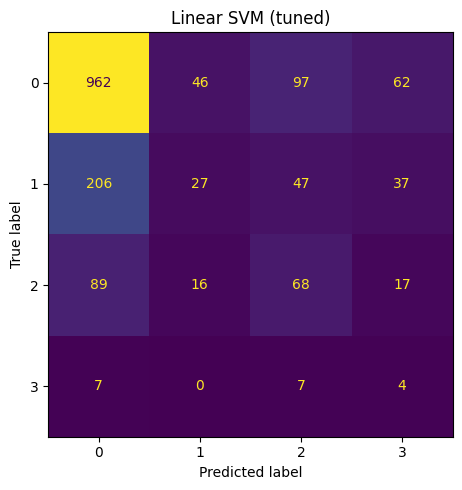

In [8]:
lin_svm = gs_lin.best_estimator_
y_pred_lin = valuta('SVM linear (tuned)', lin_svm)
plot_confusion(y_pred_lin, 'Linear SVM (tuned)')

**Commento.**
- Miglior configurazione: **C = 0.1, penalty L1, class_weight='balanced'**, F1-macro in CV **0.315**; sul test **0.329**.
- **`class_weight` è il parametro decisivo**: per ogni valore di `C` la F1-macro in CV passa da circa 0.235 (senza pesi) a circa 0.31 (con pesi). Senza pesi la SVM lineare predice quasi solo la classe 0, come nel notebook precedente (F1-macro 0.248, recall della classe 1 al 5%).
- **`C` conta pochissimo**: con `balanced` tutte le configurazioni da C = 0.001 a C = 100 stanno fra 0.310 e 0.315, tranne le combinazioni con L1 e C molto piccolo, dove la penalità azzera quasi tutti i pesi. La frontiera di decisione cambia poco perché le classi sono sovrapposte in ogni caso.
- L1 e L2 danno risultati equivalenti (0.315 contro 0.312).
- La SVM lineare ha la **ROC AUC più alta di tutte le SVM (0.695)**, ma la F1 della classe 1 resta bassa (0.133): il modello separa bene la classe 0 dalla classe 2, ma la classe 1 ("Mild"), che sta "in mezzo", viene quasi sempre confusa.

📌 **Report:** tabella del pivot `C × class_weight` (mostra in una sola tabella sia l'effetto trascurabile di `C` sia quello decisivo dei pesi) e confusion matrix.

### 5.1 Support vector del modello lineare

*liblinear* non restituisce direttamente i support vector, ma si possono ricavare dalla funzione di decisione.
Nel caso binario un punto è un support vector quando $(2y-1)\,f(x) \le 1$. Nel caso multiclasse one-vs-rest si
generalizza così: un punto sta sul margine o al suo interno quando lo score della sua classe non supera di almeno 1
il miglior score delle altre classi.

Punti sul margine o al suo interno (support vector): 5975 su 6768 (88.3%)


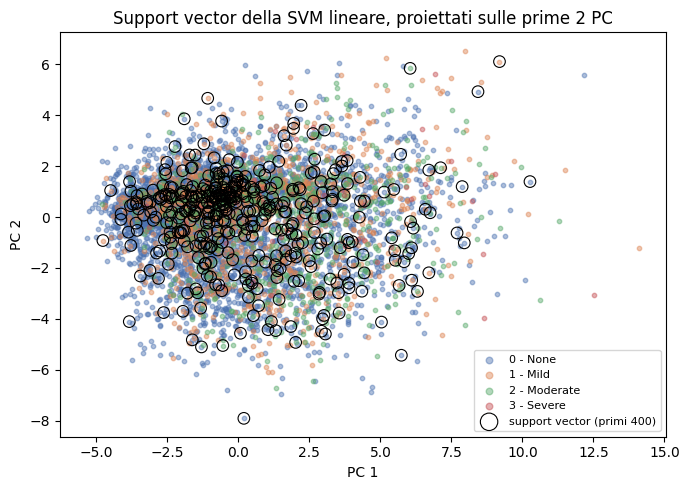

In [9]:
dec = lin_svm.decision_function(X_train)
y_idx = np.searchsorted(CLASSI, y_train.values)

own = dec[np.arange(len(y_idx)), y_idx]
masked = dec.copy()
masked[np.arange(len(y_idx)), y_idx] = -np.inf
margin = own - masked.max(axis=1)
sv_idx = np.where(margin <= 1)[0]
print(f'Punti sul margine o al suo interno (support vector): {len(sv_idx)} su {len(X_train)} '
      f'({100 * len(sv_idx) / len(X_train):.1f}%)')

sv_pca = X_pca[sv_idx]
plt.figure(figsize=(7, 5))
for i, k in enumerate(CLASSI):
    m = (y_train == k).values
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=.45, c=COLORS[i], label=NOMI_CLASSI[k])
plt.scatter(sv_pca[:400, 0], sv_pca[:400, 1], s=70, linewidth=.8, facecolors='none', edgecolors='k',
            label='support vector (primi 400)')
plt.xlabel('PC 1'); plt.ylabel('PC 2'); plt.title('Support vector della SVM lineare, proiettati sulle prime 2 PC')
plt.legend(markerscale=1.5, fontsize=8); plt.tight_layout(); plt.show()

### 5.2 Effetto di C

Per rendere visibile l'effetto del parametro di regolarizzazione, una SVM lineare viene addestrata direttamente
sulle due componenti principali, così si possono disegnare le regioni di decisione. Un `C` piccolo ammette un
margine ampio e molte violazioni, un `C` grande forza un adattamento più stretto ai punti di training.

È una proiezione **didattica** in 2D: i modelli usati per i risultati sono sempre addestrati su tutte le feature.

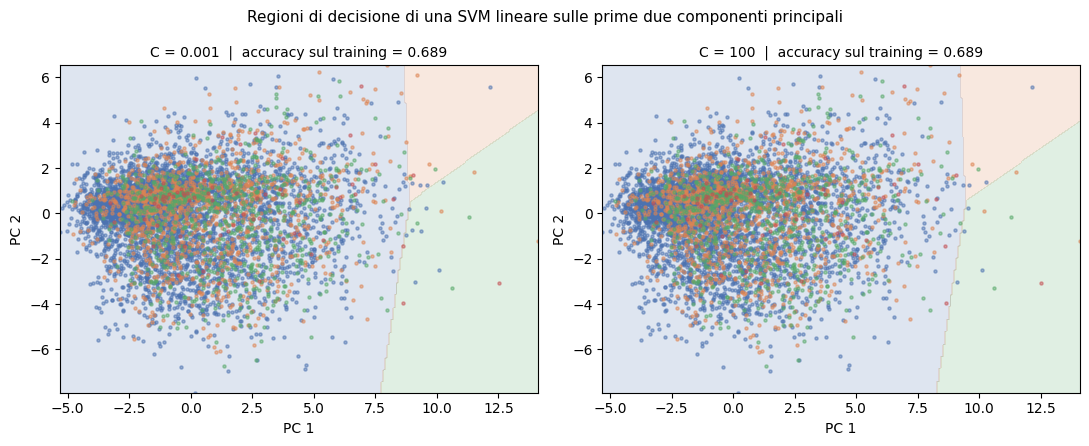

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
xx, yy = np.meshgrid(np.linspace(X_pca[:, 0].min(), X_pca[:, 0].max(), 250),
                     np.linspace(X_pca[:, 1].min(), X_pca[:, 1].max(), 250))
grid = np.c_[xx.ravel(), yy.ravel()]

for ax, C_val in zip(axes, [0.001, 100]):
    m = LinearSVC(C=C_val, random_state=RANDOM_STATE, max_iter=5000).fit(X_pca, y_train)
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.18, levels=np.arange(-.5, len(CLASSI)), colors=COLORS)
    for i, k in enumerate(CLASSI):
        msk = (y_train == k).values
        ax.scatter(X_pca[msk, 0], X_pca[msk, 1], s=5, alpha=.5, c=COLORS[i])
    ax.set_title(f'C = {C_val}  |  accuracy sul training = {m.score(X_pca, y_train):.3f}', fontsize=10)
    ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2')
plt.suptitle('Regioni di decisione di una SVM lineare sulle prime due componenti principali', fontsize=11)
plt.tight_layout(); plt.show()

**Commento.**
- **L'88,3% dei punti di training sta sul margine o al suo interno**: la SVM lineare non trova un margine "pulito" ma una frontiera diffusa attraverso classi che si sovrappongono. È la principale differenza strutturale rispetto all'esempio del breast cancer visto a lezione, dove i support vector erano una piccola frazione dei punti.
- Nel grafico dell'effetto di `C` sulle due componenti principali, **C = 0.001 e C = 100 producono praticamente la stessa frontiera** (accuracy sul training 0.689 in entrambi i casi, cioè la percentuale della classe 0): in 2D le classi sono talmente sovrapposte che il modello assegna quasi tutto il piano alla classe 0, qualunque sia la regolarizzazione. Conferma quanto visto nella grid search: `C` ha un effetto trascurabile su questo dataset.

📌 **Report:** la percentuale di support vector (88%) e una frase sull'effetto nullo di `C`; il grafico delle regioni di decisione è facoltativo.

## 6. SVM non lineare

Si confrontano tre kernel: **RBF**, **polinomiale** e **sigmoide**, ognuno con una grid search 5-fold su F1-macro.
`class_weight` (None / balanced) è incluso in tutte le griglie, come per il modello lineare.

Le griglie sono volutamente compatte: un singolo addestramento di `SVC` su questo training set richiede alcuni
secondi (la complessità cresce più che quadraticamente con il numero di esempi), quindi una griglia completa
richiederebbe migliaia di addestramenti.

| Kernel | Parametri | Significato |
|---|---|---|
| tutti | `C` | regolarizzazione (come nel lineare) |
| RBF, poly, sigmoide | `gamma` | ampiezza del kernel: `gamma` alto → frontiere più "locali" e complesse |
| poly | `degree` | grado del polinomio |

In [11]:
kernel_grids = {
    'rbf':     {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.01, 0.1]},
    'poly':    {'clf__C': [0.1, 1, 10], 'clf__gamma': ['scale', 0.1], 'clf__degree': [2, 3]},
    'sigmoid': {'clf__C': [0.1, 1, 10], 'clf__gamma': ['scale', 0.01]},
}
for g in kernel_grids.values():
    g['clf__class_weight'] = [None, 'balanced']

gs_kernel = {}
for kernel, grid in kernel_grids.items():
    t0 = time.time()
    gs = GridSearchCV(
        Pipeline([('prep', clone(preprocessor)),
                  ('clf', SVC(kernel=kernel, random_state=RANDOM_STATE, cache_size=500))]),
        grid, scoring='f1_macro', cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    gs_kernel[kernel] = gs
    print(f'{kernel:8s} {time.time() - t0:5.0f}s | migliori: '
          f'{ {k.replace("clf__", ""): v for k, v in gs.best_params_.items()} } | F1-macro CV = {gs.best_score_:.4f}')

rbf        130s | migliori: {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale'} | F1-macro CV = 0.3225
poly       134s | migliori: {'C': 0.1, 'class_weight': 'balanced', 'degree': 2, 'gamma': 'scale'} | F1-macro CV = 0.3249
sigmoid     55s | migliori: {'C': 0.1, 'class_weight': 'balanced', 'gamma': 0.01} | F1-macro CV = 0.2939


In [12]:
# Prime configurazioni di ogni kernel (da riportare nel report)
for kernel, gs in gs_kernel.items():
    print(f'--- {kernel} ---')
    display(tabella_cv(gs, kernel_grids[kernel]).head(6).round(4))

--- rbf ---


,C,gamma,class_weight,mean_test_score,std_test_score,rank_test_score
9,1.0,scale,balanced,0.3225,0.0062,1
10,1.0,0.01,balanced,0.3166,0.0063,2
16,10.0,0.01,balanced,0.3148,0.0080,3
4,0.1,0.01,balanced,0.3060,0.0143,4
15,10.0,scale,balanced,0.3036,0.0155,5
12,10.0,scale,None,0.3030,0.0159,6


--- poly ---


,C,gamma,degree,class_weight,mean_test_score,std_test_score,rank_test_score
4,0.1,scale,2,balanced,0.3249,0.0124,1
12,1.0,scale,2,balanced,0.3173,0.0134,2
6,0.1,scale,3,balanced,0.3166,0.0204,3
14,1.0,scale,3,balanced,0.3159,0.0179,4
22,10.0,scale,3,balanced,0.3118,0.0278,5
7,0.1,0.1,3,balanced,0.3110,0.0264,6


--- sigmoid ---


,C,gamma,class_weight,mean_test_score,std_test_score,rank_test_score
3,0.1,0.01,balanced,0.2939,0.0129,1
4,1.0,scale,None,0.2718,0.0189,2
7,1.0,0.01,balanced,0.2696,0.0127,3
9,10.0,0.01,None,0.2686,0.0144,4
8,10.0,scale,None,0.2683,0.0165,5
2,0.1,scale,balanced,0.2650,0.0082,6


In [13]:
for kernel, gs in gs_kernel.items():
    valuta(f'SVM {kernel} (tuned)', gs.best_estimator_, stampa=False)

tab_kernel = pd.DataFrame(risultati).set_index('modello')
tab_kernel.round(3)

,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,
SVM linear (tuned),0.627,0.372,0.329,0.695,0.791,0.133,0.333,0.058
SVM rbf (tuned),0.544,0.365,0.339,0.664,0.698,0.293,0.320,0.048
SVM poly (tuned),0.573,0.366,0.346,0.669,0.733,0.292,0.308,0.048
SVM sigmoid (tuned),0.505,0.416,0.312,0.665,0.700,0.209,0.284,0.056


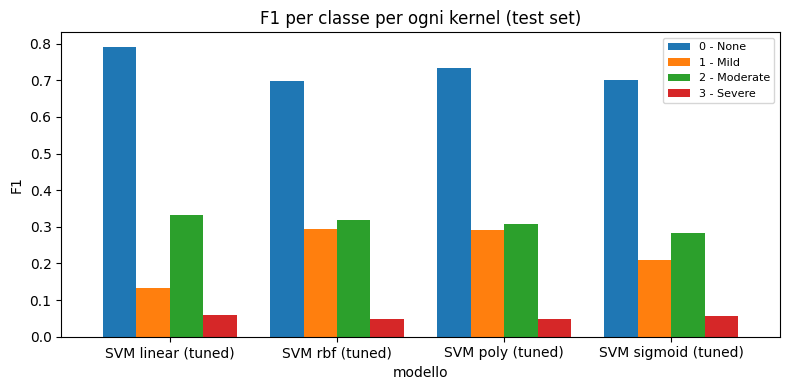

In [14]:
f1_cols = [f'f1_{k}' for k in CLASSI]
tab_kernel[f1_cols].plot(kind='bar', figsize=(8, 4), width=.8)
plt.ylabel('F1'); plt.title('F1 per classe per ogni kernel (test set)')
plt.legend([NOMI_CLASSI[k] for k in CLASSI], fontsize=8); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Commento.**

| Kernel | Parametri migliori | F1-macro CV | F1-macro test | ROC AUC |
|---|---|---|---|---|
| lineare | C=0.1, L1, balanced | 0.315 | 0.329 | 0.695 |
| RBF | C=1, gamma=scale, balanced | 0.322 | 0.339 | 0.664 |
| **polinomiale** | **C=0.1, degree=2, gamma=scale, balanced** | **0.325** | **0.346** | 0.669 |
| sigmoide | C=0.1, gamma=0.01, balanced | 0.294 | 0.312 | 0.665 |

- **Il kernel polinomiale di grado 2 è il migliore**, seguito da RBF: i kernel non lineari guadagnano circa 0.01 di F1-macro in CV rispetto al lineare. È un guadagno piccolo ma coerente fra CV e test.
- Il grado 2 batte il grado 3 (0.325 contro 0.317 in CV): servono solo **interazioni a coppie** fra le feature, non frontiere più complesse.
- I kernel non lineari migliorano soprattutto la **classe 1** (F1 da 0.133 del lineare a circa 0.29), mentre sulla classe 2 il lineare resta competitivo. La non linearità serve a separare la classe "Mild" dalle altre.
- Il kernel **sigmoide** è il peggiore in CV, ma ha la balanced accuracy più alta (0.416): classifica molti esempi nelle classi rare (recall classe 3 al 56%), a scapito della precision.
- Valori di `C` piccoli (0.1-1) sono sempre preferiti: modelli più regolarizzati generalizzano meglio, come per la NN.
- Il tempo di addestramento è il costo principale: circa 3,5-4 minuti di grid search per RBF e poly, contro 40 secondi per tutta la griglia lineare (che è anche più grande).

📌 **Report:** questa tabella e il grafico della F1 per classe per kernel.

## 7. Effetto di `class_weight`

`class_weight='balanced'` moltiplica il parametro `C` di ogni classe per un peso inversamente proporzionale alla sua
frequenza: gli errori sulle classi rare costano di più. È la strategia "a livello di algoritmo" emersa come la più
efficace nel modulo di Imbalanced Learning, e la stessa usata in LR e NN.

Per ogni kernel si confronta il miglior modello **con** e **senza** pesi (ciascuno con i propri iperparametri
migliori in CV).

In [15]:
confronto_cw = []
modelli_cw = {}
gs_tutti = {'linear': gs_lin, **gs_kernel}

for kernel, gs in gs_tutti.items():
    tab = tabella_cv(gs, gs.param_grid)
    for cw in ['None', 'balanced']:
        best = tab[tab['class_weight'] == cw].iloc[0]
        params = {k: gs.cv_results_['params'][best.name][k] for k in gs.param_grid}
        modello = clone(gs.estimator).set_params(**params).fit(X_train, y_train)
        modelli_cw[(kernel, cw)] = modello
        y_pred = modello.predict(X_test)
        confronto_cw.append({
            'kernel': kernel, 'class_weight': cw, 'F1-macro CV': best['mean_test_score'],
            'F1-macro test': f1_score(y_test, y_pred, average='macro'),
            'balanced_acc test': balanced_accuracy_score(y_test, y_pred),
            'accuracy test': accuracy_score(y_test, y_pred),
            'ROC AUC test': auc_ovr(modello.decision_function(X_test)),
            'recall classe 3': (y_pred[(y_test == 3).values] == 3).mean(),
        })

tab_cw = pd.DataFrame(confronto_cw).set_index(['kernel', 'class_weight'])
tab_cw.round(3)

F1-macro CV  F1-macro test  balanced_acc test  \
kernel  class_weight                                                  
linear  None                0.236          0.236              0.264   
        balanced            0.315          0.329              0.372   
rbf     None                0.303          0.296              0.295   
        balanced            0.322          0.339              0.365   
poly    None                0.309          0.291              0.291   
        balanced            0.325          0.346              0.366   
sigmoid None                0.272          0.254              0.264   
        balanced            0.294          0.312              0.416   

                      accuracy test  ROC AUC test  recall classe 3  
kernel  class_weight                                                
linear  None                  0.689         0.692            0.000  
        balanced              0.627         0.695            0.222  
rbf     None                  0.653         0.643            0.000  
        balanced              0.544         0.664            0.056  
poly    None                  0.594         0.594            0.000  
        balanced              0.573         0.669            0.111  
sigmoid None                  0.640         0.507            0.000  
        balanced              0.505         0.665            0.556

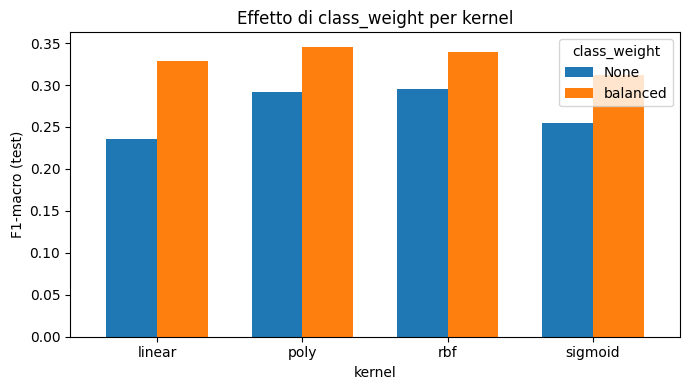

In [16]:
ax = tab_cw['F1-macro test'].unstack().plot(kind='bar', figsize=(7, 4), width=.7)
ax.set_ylabel('F1-macro (test)'); ax.set_title('Effetto di class_weight per kernel'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Commento.** Con il tuning fatto separatamente per ogni valore di `class_weight`, **i pesi migliorano tutti i kernel**:

| Kernel | F1-macro test senza pesi | con pesi | Recall classe 3 senza → con |
|---|---|---|---|
| lineare | 0.236 | **0.329** | 0% → 22% |
| RBF | 0.296 | **0.339** | 0% → 6% |
| poly | 0.291 | **0.346** | 0% → 11% |
| sigmoide | 0.254 | **0.312** | 0% → 56% |

- **Senza pesi, nessuna SVM individua un solo caso della classe 3.**
- Il guadagno è massimo per il modello lineare (+0.09): senza pesi, l'iperpiano che minimizza gli errori è quello che assegna quasi tutto alla classe 0.
- I pesi migliorano anche la **ROC AUC** dei kernel non lineari (poly da 0.594 a 0.669, sigmoide da 0.507 a 0.665), quindi non spostano solo la soglia di decisione: cambiano la frontiera appresa.
- **Differenza rispetto alla versione precedente del notebook**: lì `class_weight='balanced'` era applicato al kernel migliore senza rifare il tuning, e peggiorava i risultati (0.311 → 0.291). Rifacendo il tuning con i pesi, gli iperparametri ottimi cambiano (es. poly da C=0.1, degree 3, gamma 0.1 a C=0.1, degree 2, gamma 'scale') e il risultato migliora. **I pesi di classe vanno ottimizzati insieme agli altri iperparametri**, non aggiunti dopo.
  *Attenzione:* i numeri della versione precedente (0.311 → 0.291) sono calcolati su un altro split (70/30, `random_state=100`), quindi il confronto con i valori attuali è qualitativo. Lo stesso effetto si vede però anche **dentro questo notebook**, sullo stesso test set: per il kernel polinomiale gli iperparametri migliori senza pesi (C=10, degree 3, gamma 0.1) sono diversi da quelli migliori con i pesi (C=0.1, degree 2, gamma 'scale'), quindi aggiungere `balanced` al modello già ottimizzato senza pesi non porterebbe allo stesso risultato. (Lo 0.291 nella tabella sopra è la poly senza pesi nel nuovo run: la coincidenza con il vecchio valore è casuale.)
- È la stessa conclusione di Logistic Regression e Neural Network: in tutti e tre i classificatori `class_weight` è il parametro con l'effetto maggiore.

📌 **Report:** questa tabella e il grafico a barre; la frase sul fatto che i pesi vanno ottimizzati insieme agli altri iperparametri.

## 8. Analisi del modello migliore

Il modello con la F1-macro **in cross-validation** più alta viene analizzato in dettaglio: classification report,
confusion matrix, curve ROC e Precision-Recall one-vs-rest, numero di support vector.
(La scelta si basa sulla CV e non sul test set, per non sovrastimare le prestazioni.)

Kernel migliore (F1-macro in CV): poly
Parametri: {'C': 0.1, 'class_weight': 'balanced', 'degree': 2, 'gamma': 'scale'}
              precision    recall  f1-score   support

           0      0.788     0.686     0.733      1167
           1      0.270     0.319     0.292       317
           2      0.277     0.347     0.308       190
           3      0.031     0.111     0.048        18

    accuracy                          0.573      1692
   macro avg      0.342     0.366     0.346      1692
weighted avg      0.626     0.573     0.596      1692



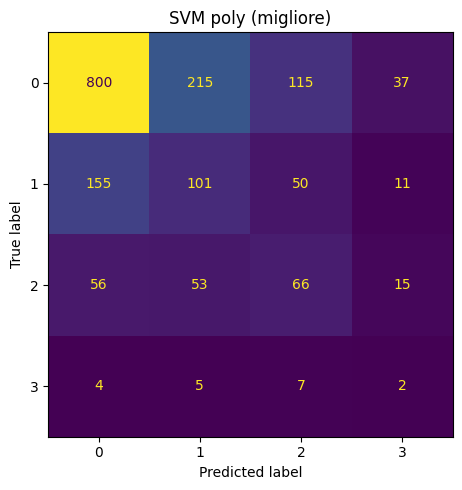

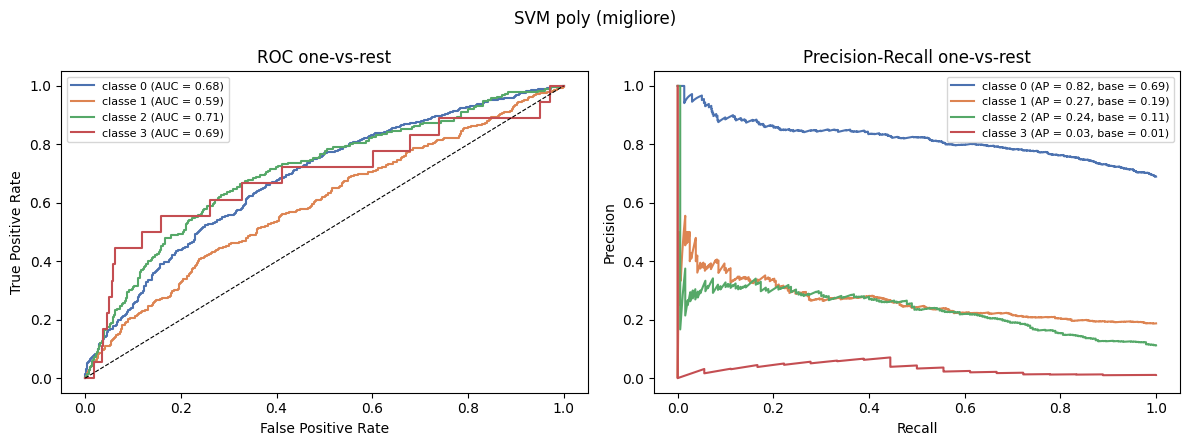

In [17]:
best_kernel = max(gs_tutti, key=lambda k: gs_tutti[k].best_score_)
best_svm = gs_tutti[best_kernel].best_estimator_
print('Kernel migliore (F1-macro in CV):', best_kernel)
print('Parametri:', {k.replace('clf__', ''): v for k, v in gs_tutti[best_kernel].best_params_.items()})

y_pred_best = best_svm.predict(X_test)
print(classification_report(y_test, y_pred_best, digits=3, zero_division=0))
plot_confusion(y_pred_best, f'SVM {best_kernel} (migliore)')
plot_roc_pr(best_svm.decision_function(X_test), f'SVM {best_kernel} (migliore)')

### 8.1 Numero di support vector

La frazione di punti di training che diventano support vector misura quanto le classi si sovrappongono nello spazio
delle feature: con classi ben separabili (come nell'esempio del breast cancer nel notebook di lezione) è piccola.

In [18]:
righe = []
for kernel in ['rbf', 'poly', 'sigmoid']:
    svc = gs_kernel[kernel].best_estimator_.named_steps['clf']
    n_sv = svc.n_support_.sum()
    righe.append({'kernel': kernel, **{f'SV classe {k}': n for k, n in zip(CLASSI, svc.n_support_)},
                  'totale SV': n_sv, '% del training': round(100 * n_sv / len(X_train), 1)})
print('Esempi di training per classe:', y_train.value_counts().sort_index().to_dict())
pd.DataFrame(righe).set_index('kernel')

Esempi di training per classe: {0: 4666, 1: 1270, 2: 762, 3: 70}


,SV classe 0,SV classe 1,SV classe 2,SV classe 3,totale SV,% del training
kernel,,,,,,
rbf,4125,1266,739,70,6200,91.6
poly,4443,1269,732,70,6514,96.2
sigmoid,4302,1270,745,64,6381,94.3


**Commento sul modello migliore (SVM polinomiale, grado 2, C=0.1, balanced).**
- F1-macro **0.346**, balanced accuracy 0.366, accuracy 0.573. Recall: classe 0 69%, classe 1 32%, classe 2 35%, classe 3 11% (2 casi su 18).
- **ROC AUC per classe**: 0.68 (classe 0), 0.59 (classe 1), 0.71 (classe 2), 0.69 (classe 3). Anche qui la classe 1 è la più difficile da separare dalle altre.
- **Precision-Recall**: per la classe 2 l'AP (0.24) è più del doppio della base (0.11); per la classe 3 l'AP è 0.03 contro una base di 0.01, quindi meglio del caso ma con una precision bassissima a qualunque soglia.
- **Support vector: fra il 92% e il 96% dei punti di training**. Per le classi 1, 2 e 3 praticamente tutti i punti sono support vector (es. 70 su 70 per la classe 3, 1269 su 1270 per la classe 1). Le classi si sovrappongono così tanto che il modello non riesce a "riassumere" la frontiera con pochi punti: memorizza quasi tutto il training set. Questo spiega anche i tempi di addestramento elevati.
- Rispetto alla versione precedente del notebook, la percentuale di support vector è più alta (prima circa 80%) perché con `class_weight='balanced'` gli errori sulle classi rare costano di più e più punti finiscono dentro il margine.

📌 **Report:** confusion matrix, curve ROC/PR e la tabella dei support vector con la frase: *"oltre il 90% dei punti di training sono support vector: le classi sono fortemente sovrapposte e non esiste un margine netto"*.

## 9. Confronto finale

### 9.1 Modelli SVM

In [19]:
tab_finale = pd.DataFrame(confronto_cw).copy()
tab_finale['modello'] = 'SVM ' + tab_finale['kernel'] + ' (cw=' + tab_finale['class_weight'] + ')'
tab_finale = tab_finale.set_index('modello').drop(columns=['kernel', 'class_weight'])
tab_finale.sort_values('F1-macro test', ascending=False).round(3)

,F1-macro CV,F1-macro test,balanced_acc test,accuracy test,ROC AUC test,recall classe 3
modello,,,,,,
SVM poly (cw=balanced),0.325,0.346,0.366,0.573,0.669,0.111
SVM rbf (cw=balanced),0.322,0.339,0.365,0.544,0.664,0.056
SVM linear (cw=balanced),0.315,0.329,0.372,0.627,0.695,0.222
SVM sigmoid (cw=balanced),0.294,0.312,0.416,0.505,0.665,0.556
SVM rbf (cw=None),0.303,0.296,0.295,0.653,0.643,0.000
SVM poly (cw=None),0.309,0.291,0.291,0.594,0.594,0.000
SVM sigmoid (cw=None),0.272,0.254,0.264,0.640,0.507,0.000
SVM linear (cw=None),0.236,0.236,0.264,0.689,0.692,0.000


### 9.2 Confronto con Logistic Regression e Neural Networks

Valori sul **test set comune** (split 80/20, `random_state=42`). I numeri di LR e NN sono copiati dai rispettivi
notebook (modelli finali, scelti in cross-validation).

In [20]:
altri = pd.DataFrame([
    {'modello': 'Logistic Regression (C=0.001, balanced)', 'accuracy': 0.505, 'balanced_acc': 0.391,
     'f1_macro': 0.311, 'roc_auc': 0.679},
    {'modello': 'Neural Network Keras (tuned)', 'accuracy': 0.496, 'balanced_acc': 0.379,
     'f1_macro': 0.320, 'roc_auc': 0.674},
])
svm_row = pd.DataFrame([r for r in risultati if r['modello'] == f'SVM {best_kernel} (tuned)'])
svm_row['modello'] = f'SVM {best_kernel} (tuned)'
dummy = {'modello': 'Dummy (most frequent)', 'accuracy': 0.690, 'balanced_acc': 0.250,
         'f1_macro': 0.204, 'roc_auc': 0.500}

confronto_modulo2 = (pd.concat([altri, svm_row[['modello', 'accuracy', 'balanced_acc', 'f1_macro', 'roc_auc']],
                                pd.DataFrame([dummy])])
                     .set_index('modello').sort_values('f1_macro', ascending=False))
confronto_modulo2.round(3)

,accuracy,balanced_acc,f1_macro,roc_auc
modello,,,,
SVM poly (tuned),0.573,0.366,0.346,0.669
Neural Network Keras (tuned),0.496,0.379,0.320,0.674
"Logistic Regression (C=0.001, balanced)",0.505,0.391,0.311,0.679
Dummy (most frequent),0.690,0.250,0.204,0.500


**Commento sul confronto del Modulo 2** (stesso test set per tutti i modelli):

| Modello | F1-macro test | F1-macro CV | Bal. acc. | ROC AUC |
|---|---|---|---|---|
| **SVM poly (grado 2)** | **0.346** | **0.325** | 0.366 | 0.669 |
| Neural Network (Keras) | 0.320 | 0.311 | 0.379 | 0.674 |
| Logistic Regression | 0.311 | 0.299 | **0.391** | **0.679** |
| Dummy | 0.204 | – | 0.250 | 0.500 |

- **La SVM polinomiale è il miglior modello del Modulo 2 per F1-macro**, sia sul test sia in cross-validation: l'ordine SVM > NN > LR è lo stesso nei due casi, quindi non dipende dal particolare test set.
- Le differenze sono però **piccole** (circa 0.02-0.03 di F1-macro) e tutti i modelli restano lontani da prestazioni utili nella pratica: il limite è nei dati (classi sovrapposte, segnale debole), non nel classificatore.
- **Le metriche non concordano sul vincitore**: la LR ha la balanced accuracy e la ROC AUC più alte, la SVM la F1-macro più alta. La SVM fa meno errori sulla classe 0 (accuracy 0.573 contro 0.505 della LR), la LR "sacrifica" più classe 0 per recuperare recall sulle classi rare. La scelta dipende dalla metrica: con la F1-macro, che è il criterio scelto per tutto il Modulo 2, vince la SVM.
- I valori di F1-macro sul test sono più alti di quelli in CV per tutti e tre i modelli: il modello finale è addestrato su tutto il training (in CV su 4/5) e la variabilità fra partizioni è di circa ±0.01-0.02.

📌 **Report:** questa tabella come confronto conclusivo del Modulo 2 (va completata con Ensemble e Gradient Boosting, se previsti).

## 10. Sintesi per il report

**Riepilogo dei risultati da riportare** (numeri del run di riferimento):

| Modello | F1-macro CV | F1-macro test | Bal. acc. | ROC AUC | Accuracy |
|---|---|---|---|---|---|
| SVM lineare (senza pesi) | 0.236 | 0.236 | 0.264 | 0.692 | 0.689 |
| SVM lineare (balanced) | 0.315 | 0.329 | 0.372 | 0.695 | 0.627 |
| SVM RBF (balanced) | 0.322 | 0.339 | 0.365 | 0.664 | 0.544 |
| **SVM poly grado 2 (balanced)** | **0.325** | **0.346** | 0.366 | 0.669 | 0.573 |
| SVM sigmoide (balanced) | 0.294 | 0.312 | 0.416 | 0.665 | 0.505 |

**Messaggi chiave per il report**
1. **Classi fortemente sovrapposte**: nella PCA le classi non si separano; l'88% dei punti è sul margine della SVM lineare e il 92-96% dei punti sono support vector nei kernel non lineari.
2. **`class_weight` è il parametro decisivo** per tutti i kernel (lineare da 0.236 a 0.329 di F1-macro); senza pesi nessuna SVM individua la classe 3.
3. **I pesi vanno ottimizzati insieme agli altri iperparametri**: aggiunti a posteriori (versione precedente) peggioravano il modello, ottimizzati insieme lo migliorano.
4. **`C` ha un effetto trascurabile** sul modello lineare (0.310–0.315 per C da 0.001 a 100); nei kernel non lineari sono preferiti valori piccoli (0.1–1), cioè modelli più regolarizzati.
5. **Non linearità utile ma limitata**: poly grado 2 e RBF guadagnano circa 0.01 in CV sul lineare, soprattutto sulla classe 1. Il grado 2 batte il grado 3: bastano interazioni a coppie fra feature.
6. **Classe peggiore: la 3** (18 esempi nel test, F1 ≤ 0.06); la classe 1 è difficile perché sta "in mezzo" fra 0 e 2.
7. **SVM poly = miglior modello del Modulo 2** per F1-macro (0.346 contro 0.320 della NN e 0.311 della LR), con lo stesso ordine in CV. La LR resta migliore per balanced accuracy e ROC AUC.
8. **Costo computazionale**: la grid search dei kernel non lineari richiede minuti, contro secondi per il modello lineare, per un guadagno di circa 0.01-0.02 di F1-macro.

**Grafici da inserire**: PCA (4), confusion matrix e ROC/PR della SVM poly (8), F1 per classe per kernel (6), effetto di `class_weight` (7).

**Tabelle da inserire**: pivot `C × class_weight` del modello lineare (5), confronto fra kernel (6), con/senza pesi (7), support vector (8.1), confronto del Modulo 2 (9.2).